In [1]:
import os
import pandas as pd
import numpy as np

In [2]:
os.getcwd()

'/home/priya'

In [3]:
#os.mkdir('oversamp_deep_learn')

In [4]:
os.chdir('oversamp_deep_learn')

In [5]:
 os.chdir('/home/priya')

In [6]:
os.getcwd()

'/home/priya'

In [7]:
 #dl=os.mkdir('deep_learn/')

In [8]:
 os.chdir('deep_learn/')

In [9]:
D_L2=os.getcwd()

In [10]:
D_L2

'/home/priya/deep_learn'

In [11]:
os.listdir()

['AttentiveFP_hptAUC_ROC_hpt.pdf',
 'GATAUC_ROC_GAT.pdf',
 'AttentiveFPAUC_ROC.pdf',
 '1st-level-filetred_cxcr4-smiles.csv',
 'GCNetworkAUC_ROC_GCNetwork.pdf',
 'GraphConvAUC_ROC.pdf',
 'DL_smiles.csv']

In [12]:
!pip install --pre deepchem[torch]
!pip install boruta
!pip install mordred

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [13]:
pip install --pre deepchem[torch]


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [14]:
 !pip install boruta
!pip install mordred

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [15]:
!pip install pymatgen 

Defaulting to user installation because normal site-packages is not writeable


In [16]:
!pip install dgl

Defaulting to user installation because normal site-packages is not writeable


In [17]:
#importing libraries
import deepchem as dc
import pickle
import tensorflow as tf
from deepchem.feat import MolGraphConvFeaturizer
from deepchem.feat.graph_data import GraphData
from deepchem.feat.mol_graphs import ConvMol
from deepchem.data import NumpyDataset
from imblearn.over_sampling import SMOTE
from sklearn import preprocessing
import warnings
warnings.filterwarnings("ignore")
import joblib
from boruta import BorutaPy
from collections import Counter
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier
from sklearn.metrics import accuracy_score,roc_auc_score,cohen_kappa_score,f1_score,precision_score,recall_score,roc_curve,auc
from sklearn import metrics
from sklearn.model_selection import StratifiedKFold
import imblearn
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
from statistics import mean
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import roc_curve, auc
from mordred import Calculator, descriptors
from rdkit import Chem
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
import sys
import dgl
import matplotlib.pyplot as plt
import sklearn

2022-09-24 02:14:43.432055: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-09-24 02:14:43.675270: I tensorflow/core/util/util.cc:169] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2022-09-24 02:14:43.681611: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2022-09-24 02:14:43.681630: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if yo

In [18]:
def seed_all():
    np.random.seed(123)
    tf.random.set_seed(123)
seed_all()

In [19]:
data=pd.read_csv(r'/home/priya/DL_smiles.csv')

In [20]:
data.head(5)

,SMILES,ACTIVITY
0,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,active
1,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,active
2,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,active
3,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,inactive
4,CC(C)[C@H](NC(=O)C[C@H](O)[C@H](Cc1cc(F)cc(F)c...,active


In [21]:
data_col=['smiles','activity']
data.columns=data_col

In [22]:
data = data.replace('active',0 )
data=data.replace('inactive',1)

In [23]:
Dat=data

In [24]:
data.head(5)

,smiles,activity
0,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,0
1,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,0
2,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,0
3,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,1
4,CC(C)[C@H](NC(=O)C[C@H](O)[C@H](Cc1cc(F)cc(F)c...,0


In [25]:
Dat.head(5)

,smiles,activity
0,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,0
1,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,0
2,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,0
3,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,1
4,CC(C)[C@H](NC(=O)C[C@H](O)[C@H](Cc1cc(F)cc(F)c...,0


In [26]:
def MolGraphConv(df):
    featurizer = dc.feat.MolGraphConvFeaturizer(use_edges=True)
    mols = [Chem.MolFromSmiles(smiles) for smiles in df["smiles"]]
    features = featurizer.featurize(mols)
    dataset = dc.data.NumpyDataset(X=features, y=df["activity"], ids=df["smiles"]) 
    return dataset
def ConvMol(df):
    featurizer = dc.feat.ConvMolFeaturizer()
    mols = [Chem.MolFromSmiles(smiles) for smiles in df["smiles"]]
    features = featurizer.featurize(mols)
    dataset = dc.data.NumpyDataset(X=features, y=df["activity"], ids=df["smiles"])  
    return dataset
def CGCNN(df):
    featurizer = dc.feat.CGCNNFeaturizer()
    mols = [Chem.MolFromSmiles(smiles) for smiles in df["smiles"]]
    features = featurizer.featurize(mols)
    dataset = dc.data.NumpyDataset(X=features, y=df["activity"], ids=df["smiles"])  
    return dataset
def PagtnMolGraph(df):
    featurizer = dc.feat.PagtnMolGraphFeaturizer(max_length=5)
    mols = [Chem.MolFromSmiles(smiles) for smiles in df["smiles"]]
    features = featurizer.featurize(mols)
    dataset = dc.data.NumpyDataset(X=features, y=df["activity"], ids=df["smiles"])  
    return dataset
def get_labels_2(pred_test): #Getting discrete labels from probability values    
    test_pred = [] 
    test_probs= []
    for i in range(pred_test.shape[0]):
        test_probs.append(pred_test[i][0][1])
        if(pred_test[i][0][0]>pred_test[i][0][1]):
            test_pred.append(0)
        else:
            test_pred.append(1)
    return test_pred,test_probs
def get_labels(pred_test): #Getting discrete labels from probability values    
    test_pred = [] 
    test_probs= []
    for i in range(pred_test.shape[0]):
        test_probs.append(pred_test[i][1])
        if(pred_test[i][0]>pred_test[i][1]):
            test_pred.append(0)
        else:
            test_pred.append(1)
    return test_pred,test_probs

In [27]:
def generate_dataset_GraphData(data,feat):  
    smiles = data['smiles']
    status=data['activity']
    featurizer = feat
    features = featurizer.featurize(smiles)  
    indices = [ i for i, data in enumerate(features) if type(data) is not GraphData] #indices which failed to featurize  
    return indices
def generate_dataset_ConvMol(data,feat):  
    smiles = data['smiles']
    featurizer = feat
    features = featurizer.featurize(smiles)  
    indices = [ i for i, data in enumerate(features) if type(data) is not ConvMol]   
    return indices

In [28]:
feat = dc.feat.MolGraphConvFeaturizer() #used for cxcr4 receptor datasets
while True:# remove all error producing samples
    indices = generate_dataset_GraphData(Dat,feat)
    if len(indices) > 0: #keep removing unless there are no error prone samples
        Dat.drop(index=indices,inplace=True)
    else:
        break
    print('After MolGraphConv screening',len(Dat))

In [29]:
Dat.to_csv('1st-level-filetred_cxcr4-smiles.csv',index=False)#After 1st level of filtering

In [30]:
# CMtrain.X

# OverSampling

In [31]:
splitter = dc.splits.ScaffoldSplitter()
MGFeatures=MolGraphConv(Dat)
MGtrain, MGtest = splitter.train_test_split(MGFeatures,seed=10)
CMFeatures=ConvMol(Dat)
CMtrain, CMtest = splitter.train_test_split(CMFeatures,seed=10)
transformer=dc.trans.DuplicateBalancingTransformer(dataset=CMtrain)
CMtrain=transformer.transform(CMtrain)

In [32]:
pd.DataFrame(CMtrain.y).value_counts() #before oversampling

0    3810
1    3440
dtype: int64

In [33]:
pd.DataFrame(CMtrain.y).value_counts() #after oversampling

0    3810
1    3440
dtype: int64

In [34]:
MGtrain

<NumpyDataset X.shape: (4670,), y.shape: (4670,), w.shape: (4670,), task_names: [0]>

In [35]:
MGtest

<NumpyDataset X.shape: (1168,), y.shape: (1168,), w.shape: (1168,), task_names: [0]>

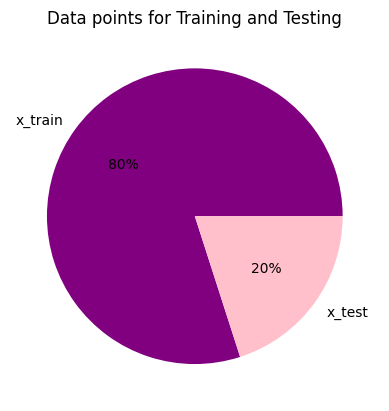

In [36]:
#pie chart

x = [774,194]
labels = ['x_train','x_test']

fig, ax = plt.subplots()
ax.pie(x, labels = labels,colors=['purple','pink'],autopct='%.0f%%')
ax.set_title('Data points for Training and Testing')
plt.show()

In [37]:
MGFeatures

<NumpyDataset X.shape: (5838,), y.shape: (5838,), w.shape: (5838,), task_names: [0]>

In [38]:
print(MGFeatures.X)

 <deepchem.feat.graph_data.GraphData object at 0x7f7f01267790> ...


In [39]:
print(type(MGFeatures))

<class 'deepchem.data.datasets.NumpyDataset'>


# Saving Features

In [40]:
MGFeat_data =pd.DataFrame()#to fetch MGtest data
MGFeat_data["smiles"]= MGtest.ids
MGFeat_data["y_shape"]= MGtest.y
MGFeat_data["x_shape"]= MGtest.X
MGFeat_data["w_shape"]= MGtest.w
# MGFeat_data
MGFeat_data.to_csv("/home/priya/MGFeat_data1_afteroversamp.csv")

In [41]:
MGFeat_data

,smiles,y_shape,x_shape,w_shape
0,Cn1nc(Nc2cccc([C@]3(C)COCC(N)=N3)c2)c2ccccc21,1,<deepchem.feat.graph_data.GraphData object at ...,1.0
1,COc1ccccc1Nc1ccc(F)c([C@]2(C)CO[C@@](C)(C(F)(F...,1,<deepchem.feat.graph_data.GraphData object at ...,1.0
2,C[C@@]1(c2nc(Nc3ncnc4cc(C(F)(F)F)cnc34)ccc2F)C...,0,<deepchem.feat.graph_data.GraphData object at ...,1.0
3,Cc1cc(C(=O)Nc2ccc(F)c([C@]3(C)C=CSC(N)=N3)c2)n...,0,<deepchem.feat.graph_data.GraphData object at ...,1.0
4,C[C@@]1(c2cc(NC(=O)c3ccc(C#N)cn3)ccc2F)CS(=O)(...,0,<deepchem.feat.graph_data.GraphData object at ...,1.0
...,...,...,...,...
1163,CC(C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N[C@@H...,0,<deepchem.feat.graph_data.GraphData object at ...,1.0
1164,CCC(C)C[C@H](NC(=O)C[C@H](O)[C@H](Cc1ccccc1)NC...,0,<deepchem.feat.graph_data.GraphData object at ...,1.0
1165,c1ccc(-c2ccc(COc3ccc4c(c3)CCC(CCN3CCCCC3)C4)cc...,0,<deepchem.feat.graph_data.GraphData object at ...,1.0
1166,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,0,<deepchem.feat.graph_data.GraphData object at ...,1.0


# SAVING MGtest and MGtrain data

In [42]:
test_data =pd.DataFrame()#to fetch MGtest data
test_data["smiles"]= MGtest.ids
test_data["status"]= MGtest.y
test_data
test_data.to_csv("/home/priya/testing_data1_afteroversamp.csv")

In [43]:
train_data =pd.DataFrame()#to fetch MGtrain data
train_data["smiles"]= MGtrain.ids
train_data["status"]= MGtrain.y
train_data.to_csv("/home/priya/training_data1_afteroversamp.csv")

In [44]:
D_L2

'/home/priya/deep_learn'

# GraphConv MODEL

In [45]:
deep_model='GraphConv'
CMmodel = dc.models.GraphConvModel(mode='classification',n_tasks=1,batch_size=32,learning_rate=0.001,model_dir=D_L2 + deep_model)
CMmodel.fit(CMtrain, nb_epoch=50)

2022-09-24 02:17:14.476203: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2022-09-24 02:17:14.478540: W tensorflow/stream_executor/cuda/cuda_driver.cc:263] failed call to cuInit: UNKNOWN ERROR (303)
2022-09-24 02:17:14.478609: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (NeurocareeLAB): /proc/driver/nvidia/version does not exist
2022-09-24 02:17:14.497884: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


0.06266860961914063

Training set score: {'roc_auc_score': 0.9981992003906488}
Test set score: {'roc_auc_score': 0.904469848828651}
Training Accuracy : 0.9775172413793104
Testing Accuracy: 0.8467465753424658
MCC Score: 0.6441718600467785
F1 Score: 0.822066231545729
kappa Score: 0.6441400345865276
AUC VALUE: 0.904470696772049


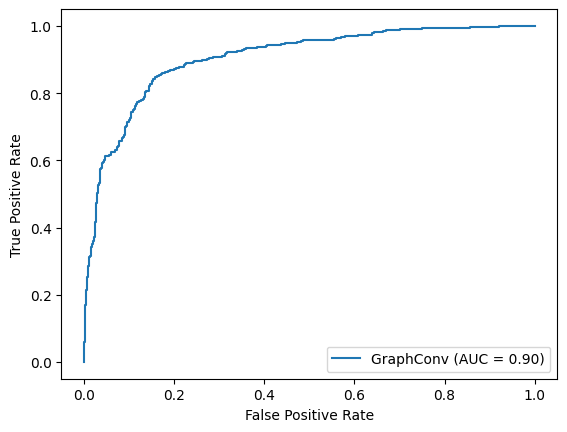

              precision    recall  f1-score   support

           0       0.89      0.89      0.89       799
           1       0.76      0.75      0.76       369

    accuracy                           0.85      1168
   macro avg       0.82      0.82      0.82      1168
weighted avg       0.85      0.85      0.85      1168



In [46]:
CMmetric = dc.metrics.Metric(dc.metrics.roc_auc_score)
print('Training set score:', CMmodel.evaluate(CMtrain, [CMmetric]))
print('Test set score:', CMmodel.evaluate(CMtest, [CMmetric]))
train_probs = CMmodel.predict(CMtrain)
train_labels,train_preds = get_labels_2(train_probs)
test_probs = CMmodel.predict(CMtest)
test_labels,test_preds = get_labels_2(test_probs)
print("Training Accuracy :",metrics.accuracy_score(CMtrain.y, train_labels))
print("Testing Accuracy:",metrics.accuracy_score(CMtest.y, test_labels))
print("MCC Score:",matthews_corrcoef(CMtest.y, test_labels))
print("F1 Score:",f1_score(CMtest.y, test_labels, average='macro'))
kappa_rf=sklearn.metrics.cohen_kappa_score(CMtest.y,test_labels)
print("kappa Score:",kappa_rf)
fpr_rf, tpr_rf, _ = roc_curve(CMtest.y,test_preds)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print("AUC VALUE:",roc_auc_rf)
display = metrics.RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf,estimator_name=deep_model)
display.plot()
plt.savefig(deep_model+'AUC_ROC.pdf')
plt.show()
res=sklearn.metrics.classification_report(CMtest.y, test_labels)
print(res)

In [47]:
# python3 -c import dgl

# Attentive

In [48]:
deep_model='AttentiveFP'
AtFPmodel = dc.models.AttentiveFPModel(n_tasks=1,mode='classification',num_layers=2,graph_feat_size=200,dropout=0.5,batch_size=32, learning_rate=0.001,model_dir=D_L2 + deep_model)
AtFPmodel.fit(MGtrain,nb_epoch=100)

0.04875486373901367

In [49]:
pip install dgllife

Defaulting to user installation because normal site-packages is not writeable
  Using cached scikit_learn-0.24.2-cp310-cp310-linux_x86_64.whl
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.1.2
    Uninstalling scikit-learn-1.1.2:
      Successfully uninstalled scikit-learn-1.1.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
imbalanced-learn 0.9.1 requires scikit-learn>=1.1.0, but you have scikit-learn 0.24.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [50]:
AtFPmetric = dc.metrics.Metric(dc.metrics.roc_auc_score)
print('Training set score:', AtFPmodel.evaluate(MGtrain, [AtFPmetric]))
print('Test set score:', AtFPmodel.evaluate(MGtest, [AtFPmetric]))
train_probs = AtFPmodel.predict(MGtrain)

Training set score: {'roc_auc_score': 0.9989396783250931}
Test set score: {'roc_auc_score': 0.8736623692895251}


Training Accuracy : 0.9839400428265525
Testing Accuracy: 0.8356164383561644
MCC Score: 0.6081929479578705
F1 Score: 0.8018764908560827
kappa Score: 0.6046973217087195
AUC VALUE: 0.873659825459331


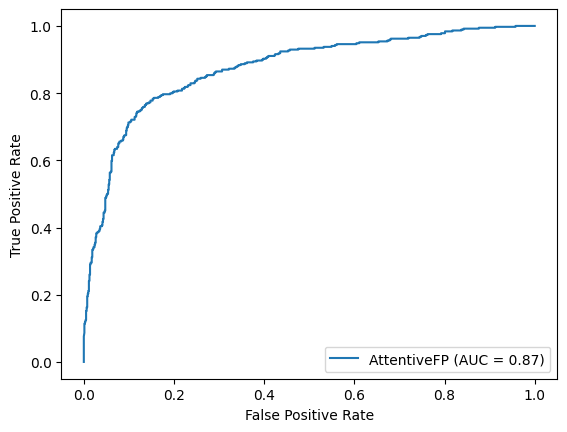

              precision    recall  f1-score   support

           0       0.86      0.91      0.88       799
           1       0.78      0.67      0.72       369

    accuracy                           0.84      1168
   macro avg       0.82      0.79      0.80      1168
weighted avg       0.83      0.84      0.83      1168



In [51]:
train_labels,train_preds = get_labels(train_probs)
test_probs = AtFPmodel.predict(MGtest)
test_labels,test_preds = get_labels(test_probs)
print("Training Accuracy :",metrics.accuracy_score(MGtrain.y, train_labels))
print("Testing Accuracy:",metrics.accuracy_score(MGtest.y, test_labels))
print("MCC Score:",matthews_corrcoef(MGtest.y, test_labels))
print("F1 Score:",f1_score(MGtest.y, test_labels, average='macro'))
kappa_rf=sklearn.metrics.cohen_kappa_score(MGtest.y,test_labels)
print("kappa Score:",kappa_rf)
fpr_rf, tpr_rf, _ = roc_curve(MGtest.y,test_preds)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print("AUC VALUE:",roc_auc_rf)
display = metrics.RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf,estimator_name=deep_model)
display.plot()
plt.savefig(deep_model+'AUC_ROC.pdf')
plt.show()
res=sklearn.metrics.classification_report(MGtest.y, test_labels)
print(res)

# GCN

In [52]:
deep_model='GCNetwork'
GCNmodel = dc.models.GCNModel(n_tasks=1,mode='classification',graph_conv_layers=[64,64], predictor_hidden_feats=64,predictor_dropout = 0.2, Learning_rate = 0.001, batch_size = 32,model_dir=D_L2 + deep_model)
GCNmodel.fit(MGtrain,nb_epoch=100)

0.1717900276184082

Training set score: {'roc_auc_score': 0.9819899438442288}
Test set score: {'roc_auc_score': 0.9113135999945731}
Training Accuracy : 0.9550321199143469
Testing Accuracy: 0.8493150684931506
MCC Score: 0.6396469599102013
F1 Score: 0.81583558796653
kappa Score: 0.63319070272045
AUC VALUE: 0.9113135999945732


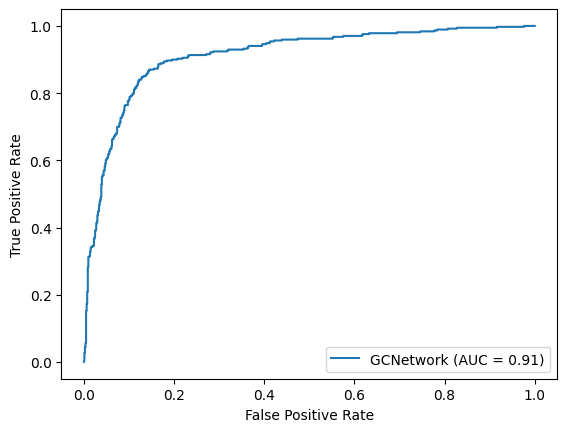

              precision    recall  f1-score   support

           0       0.86      0.93      0.89       799
           1       0.82      0.67      0.74       369

    accuracy                           0.85      1168
   macro avg       0.84      0.80      0.82      1168
weighted avg       0.85      0.85      0.84      1168



In [53]:
GCNmetric = dc.metrics.Metric(dc.metrics.roc_auc_score)
print('Training set score:', GCNmodel.evaluate(MGtrain, [GCNmetric]))
print('Test set score:', GCNmodel.evaluate(MGtest, [GCNmetric]))
train_probs = GCNmodel.predict(MGtrain)
train_labels,train_preds = get_labels(train_probs)
test_probs = GCNmodel.predict(MGtest)
test_labels,test_preds = get_labels(test_probs)
print("Training Accuracy :",metrics.accuracy_score(MGtrain.y, train_labels))
print("Testing Accuracy:",metrics.accuracy_score(MGtest.y, test_labels))
print("MCC Score:",matthews_corrcoef(MGtest.y, test_labels))
print("F1 Score:",f1_score(MGtest.y, test_labels, average='macro'))
kappa_rf=sklearn.metrics.cohen_kappa_score(MGtest.y,test_labels)
print("kappa Score:",kappa_rf)
fpr_rf, tpr_rf, _ = roc_curve(MGtest.y,test_preds)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print("AUC VALUE:",roc_auc_rf)
display = metrics.RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf,estimator_name=deep_model)
display.plot()
plt.savefig(deep_model+'AUC_ROC_GCNetwork.pdf')
plt.show()
res=sklearn.metrics.classification_report(MGtest.y, test_labels)
print(res)

# GAT

In [54]:
deep_model='GAT'
GATmodel = dc.models.GATModel(mode='classification', n_tasks=1,batch_size=16, learning_rate=0.001,model_dir=D_L2 + deep_model)
GATmodel.fit(MGtrain, nb_epoch=5)

0.3410334587097168

Training set score: {'roc_auc_score': 0.8480037233717879}
Test set score: {'roc_auc_score': 0.7798688061974488}
Training Accuracy : 0.839186295503212
Testing Accuracy: 0.7397260273972602
MCC Score: 0.40772125796384573
F1 Score: 0.7035532994923858
kappa Score: 0.40734608310160536
AUC VALUE: 0.7798705020842449


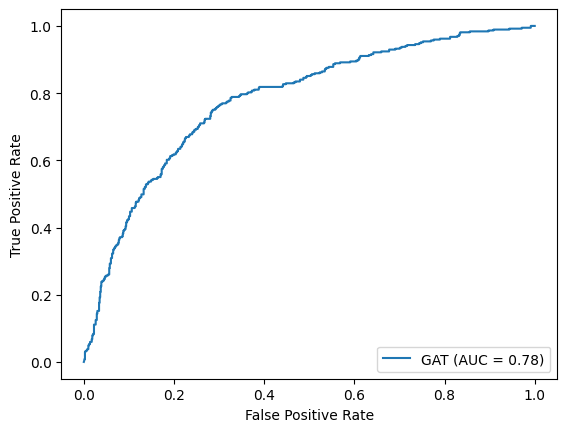

              precision    recall  f1-score   support

           0       0.82      0.80      0.81       799
           1       0.58      0.62      0.60       369

    accuracy                           0.74      1168
   macro avg       0.70      0.71      0.70      1168
weighted avg       0.74      0.74      0.74      1168



In [55]:
GATmetric = dc.metrics.Metric(dc.metrics.roc_auc_score)
print('Training set score:', GATmodel.evaluate(MGtrain, [GATmetric]))
print('Test set score:', GATmodel.evaluate(MGtest, [GATmetric]))
train_probs = GATmodel.predict(MGtrain)
train_labels,train_preds = get_labels(train_probs)
test_probs = GATmodel.predict(MGtest)
test_labels,test_preds = get_labels(test_probs)
print("Training Accuracy :",metrics.accuracy_score(MGtrain.y, train_labels))
print("Testing Accuracy:",metrics.accuracy_score(MGtest.y, test_labels))
print("MCC Score:",matthews_corrcoef(MGtest.y, test_labels))
print("F1 Score:",f1_score(MGtest.y, test_labels, average='macro'))
kappa_rf=sklearn.metrics.cohen_kappa_score(MGtest.y,test_labels)
print("kappa Score:",kappa_rf)
fpr_rf, tpr_rf, _ = roc_curve(MGtest.y,test_preds)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print("AUC VALUE:",roc_auc_rf)
display = metrics.RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf,estimator_name=deep_model)
display.plot()
plt.savefig(deep_model+'AUC_ROC_GAT.pdf')
plt.show()
res=sklearn.metrics.classification_report(MGtest.y, test_labels)
print(res)

# PMG

In [56]:
deep_model='PMG'
PMGFeatures=PagtnMolGraph(Dat)
PMGtrain, PMGtest = splitter.train_test_split(PMGFeatures,seed=10)
PMGNmodel = dc.models.PagtnModel(mode='classification', n_tasks=1, batch_size=32, learning_rate=0.001,model_dir=D_L2 + deep_model)
PMGNmodel.fit(PMGtrain, nb_epoch=50)

AttributeError: module 'deepchem.feat' has no attribute 'PagtnMolGraphFeaturizer'

In [ ]:
PMGNmetric = dc.metrics.Metric(dc.metrics.roc_auc_score)
print('Training set score:', PMGNmodel.evaluate(PMGtrain, [PMGNmetric]))
print('Test set score:', PMGNmodel.evaluate(PMGtest, [PMGNmetric]))
train_probs = PMGNmodel.predict(PMGtrain)
train_labels,train_preds = get_labels(train_probs)
test_probs = PMGNmodel.predict(PMGtest)
test_labels,test_preds = get_labels(test_probs)
print("Training Accuracy :",metrics.accuracy_score(PMGtrain.y, train_labels))
print("Testing Accuracy:",metrics.accuracy_score(PMGtest.y, test_labels))
print("MCC Score:",matthews_corrcoef(PMGtest.y, test_labels))
print("F1 Score:",f1_score(PMGtest.y, test_labels, average='macro'))
kappa_rf=sklearn.metrics.cohen_kappa_score(PMGtest.y,test_labels)
print("kappa Score:",kappa_rf)
fpr_rf, tpr_rf, _ = roc_curve(PMGtest.y,test_preds)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print("AUC VALUE:",roc_auc_rf)
display = metrics.RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf,estimator_name=deep_model)
display.plot()
plt.savefig(deep_model+'AUC_ROC_PMG.pdf')
plt.show()
res=sklearn.metrics.classification_report(MGtest.y, test_labels)
print(res)

# Attentive

In [ ]:
test_probs1 = AtFPmodel.predict(MGtest)
test_probs1

In [ ]:
train_probs

# installation

In [ ]:
!pip install pyGPGO

# Hyperparameter tuning

In [ ]:
#hyperparameter tuning(Model)

# Fit models
AtFPmetric = dc.metrics.Metric(dc.metrics.roc_auc_score)
optimizer = dc.hyper.GaussianProcessHyperparamOpt(
    lambda **p: dc.models.AttentiveFPModel(n_tasks= 1 , mode="classification", **p))

params_dict = {"dropout": 0.5,"batch_size":32,"learning_rate":0.001}
best_model, best_params, all_results = optimizer.hyperparam_search(params_dict,
    MGtrain, MGtest , AtFPmetric,  search_range=2)

valid_score = best_model.evaluate(MGtest, [AtFPmetric] )
print("valid_score")


In [ ]:
valid_score

In [ ]:
best_params

# ATTENTIVE

In [ ]:
deep_model='AttentiveFP_hpt'
AtFPmodel2 = dc.models.AttentiveFPModel(n_tasks=1,mode='classification',num_layers=2,graph_feat_size=200,dropout=0.25,batch_size=57, learning_rate=0.0005,model_dir=D_L2 + deep_model)
AtFPmodel2.fit(MGtrain,nb_epoch=100)

In [ ]:
AtFPmetric2 = dc.metrics.Metric(dc.metrics.roc_auc_score)
print('Training set score:', AtFPmodel2.evaluate(MGtrain, [AtFPmetric]))
print('Test set score:', AtFPmodel2.evaluate(MGtest, [AtFPmetric]))
train_probs = AtFPmodel2.predict(MGtrain)

In [ ]:
train_labels,train_preds = get_labels(train_probs)
test_probs = AtFPmodel2.predict(MGtest)
test_labels,test_preds = get_labels(test_probs)
print("Training Accuracy :",metrics.accuracy_score(MGtrain.y, train_labels))
print("Testing Accuracy:",metrics.accuracy_score(MGtest.y, test_labels))
print("MCC Score:",matthews_corrcoef(MGtest.y, test_labels))
print("F1 Score:",f1_score(MGtest.y, test_labels, average='macro'))
kappa_rf=sklearn.metrics.cohen_kappa_score(MGtest.y,test_labels)
print("kappa Score:",kappa_rf)
fpr_rf, tpr_rf, _ = roc_curve(MGtest.y,test_preds)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print("AUC VALUE:",roc_auc_rf)
display = metrics.RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf,estimator_name=deep_model)
display.plot()
plt.savefig(deep_model+'AUC_ROC_hpt.pdf')
plt.show()
res=sklearn.metrics.classification_report(MGtest.y, test_labels)
print(res)

# Confusion Matrix

In [ ]:
r = sklearn.metrics.confusion_matrix(test_labels,MGtest.y)
print(r)

In [ ]:
from sklearn.metrics import plot_confusion_matrix
import seaborn as sns

In [ ]:
pip install seaborn 

In [ ]:
pl_ot=plot_confusion_matrix( test_labels,MGtest.y,cmap='cividis',colorbar=False)

# Model reload

In [ ]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred_class)
print(cm)
reloaded_model = dc.models.AttentiveFPModel(n_tasks=1,mode='classification',num_layers=2,graph_feat_size=200,dropout=0.6907786562733176,batch_size=32, learning_rate=0.001499965068138524,model_dir=D_L2 + deep_model)
reloaded_model.restore()


In [ ]:
dla_test_probs=reloaded_model.predict(MGtest)

In [ ]:
dla_test_probs

In [ ]:
print(type(dla_test_probs))

In [ ]:
df_test_prob=pd.DataFrame(dla_test_probs) #converting df_test_prob(predicted test data) into DataFrame

In [ ]:
df_test_prob.shape

In [ ]:
df_test_prob

In [ ]:
df_test_prob['smiles'] = MGtest. ids #Saving it's status and smiles into it
df_test_prob['status'] = MGtest.y

In [ ]:
df_test_prob

In [ ]:
df_test_prob.to_csv("result_of_test_data_prediction_hpt.csv") #to save into csv

# confusion matrix

In [ ]:
MGtrain

# KFOLD cross validation

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
os.getcwd()

# splitting of training DATA

In [ ]:
split_datas = splitter.k_fold_split(MGtrain,10)

In [ ]:
split_datas[0][1]

# MODEL AFTER DOING 10 FOLD CROSS VALIDATION

In [ ]:

i=0
for dset in split_datas:
    dset[0]
    dset[1]
    i+=1
    deep_model='Attentive_cv'+str(i)
    AtFPmodel3 = dc.models.AttentiveFPModel(n_tasks=1,mode='classification',num_layers=2,graph_feat_size=200,dropout=0.562425842496346,batch_size=43, learning_rate=0.0014496389979131632,model_dir=D_L2 + deep_model)
    AtFPmodel3.fit(dset[0],nb_epoch=100)
    AtFPmetric3 = dc.metrics.Metric(dc.metrics.roc_auc_score)
    train_probs = AtFPmodel3.predict(dset[1])
    print('Training set score:', AtFPmodel3.evaluate(dset[0], [AtFPmetric3]))
    print('Test set score:', AtFPmodel3.evaluate(MGtest, [AtFPmetric3]))
    train_labels,train_preds = get_labels(train_probs)
    test_probs = AtFPmodel3.predict(MGtest)
    test_labels,test_preds = get_labels(test_probs)
#     print("Training Accuracy :",metrics.accuracy_score(dset[0].y, train_labels))
    print("Testing Accuracy:",metrics.accuracy_score(MGtest.y, test_labels))
    print("MCC Score:",matthews_corrcoef(MGtest.y, test_labels))
    print("F1 Score:",f1_score(MGtest.y, test_labels, average='macro'))
    kappa_rf=sklearn.metrics.cohen_kappa_score(MGtest.y,test_labels)
    print("kappa Score:",kappa_rf)
    fpr_rf, tpr_rf, _ = roc_curve(MGtest.y,test_preds)
    roc_auc_rf = auc(fpr_rf, tpr_rf)
    print("AUC VALUE:",roc_auc_rf)
    display = metrics.RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf,estimator_name=deep_model)
    display.plot()
    plt.savefig(deep_model+'AUC_ROC_cv.pdf')
    plt.show()
    res=sklearn.metrics.classification_report(MGtest.y, test_labels)
    print(res)

    
    

In [ ]:
# cm=confusion_matrix(MGtest.y,test_probs.y)
# print(cm)
dla_test_probss=reloaded_model.predict(MGtrain)
# print(attentive_model_probs)

In [ ]:
dla_train_probss #it's train data only

In [ ]:
print(type(dla_train_probss))  #it's train data only

In [ ]:
df_test_prob=pd.DataFrame(dla_train_probss) #it's train data only
# df_test_prob_res=df_test_prob(dla_test_probss)

In [ ]:
df_train_prob #name mistake,it's train data only

In [ ]:
# df_test_prob['smiles']=MGtest.ids

# Metabolites

In [ ]:
m_dat=pd.read_csv(r'/home/priya/MolGraphConv_screened-metabolites_hum_smls.csv')


In [ ]:
m_dat

In [ ]:
m_dat.head(5)

In [ ]:
m_dat.shape

In [ ]:
# featu = MolGraphConvFeaturizer(use_edges=True)
# out1 = featu.featurize(smiles1['SMILES'])

In [ ]:
m_dat.drop('Unnamed: 0',axis=1,inplace=True)


In [ ]:
m_dat

In [ ]:
# FEATURE EXTRACTION OF METABOLITES

In [ ]:
met_featu = MolGraphConvFeaturizer(use_edges=True)
met_out = met_featu.featurize(m_dat['smiles'])
                                                    

In [ ]:
met_out

# Feature extraction(Metabolites)

In [ ]:
met_out.shape

#  dataframe

In [ ]:
met_dt_out=dc.data.NumpyDataset(X=met_out,ids=m_dat)

In [ ]:
met_dt_out

In [ ]:
met_dt_out. X

In [ ]:
met_dt_out.y

In [ ]:
# save metabolites features
met_dt =pd.DataFrame()#to fetch MGtest data
met_dt["Feat"]= met_dt_out.X
met_dt["status"]= met_dt_out.y
met_dt
met_dt.to_csv("/home/priya/met_dt_feat_hpt.csv")